# [기초-실습] 통계 101×데이터 분석: (4장) 추론통계~신뢰구간

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

In [3]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import koreanize_matplotlib   # 이 import가 핵심

print("현재 폰트:", plt.rcParams['font.family'])
print("한글 폰트 목록:", sorted({f.name for f in fm.fontManager.ttflist if 'Nanum' in f.name}))

현재 폰트: ['NanumGothic']
한글 폰트 목록: ['NanumGothic']


# 문제 1. 표본조사 체험하기

**📘 문제**

- 온라인 쇼핑몰은 전체 고객 수가 너무 많아, 모든 고객을 조사하기 어렵습니다.

- 그래서 무작위로 고객 30명을 뽑아 평균 만족도를 계산하고 이를 전체 만족도의 추정값으로 사용하려 합니다.

- 이번 실습에서는 직접 표본을 뽑고, 표본 평균을 구해보며,
  **“표본마다 결과가 달라질 수 있다”**는 추론 통계의 핵심 개념을 체험해봅니다.

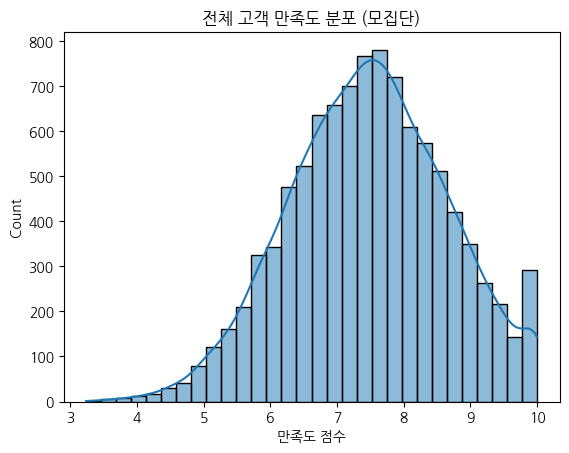

In [22]:
# 모집단 생성 (전체 고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.5, scale=1.2, size=10000)
population = np.clip(population, 1, 10)  # 1점 ~ 10점 사이로 제한
df_pop = pd.DataFrame({'score': population})

# 전체 모집단 시각화
sns.histplot(df_pop['score'], bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 표본을 무작위로 여러 번 뽑아 보고, 표본 평균이 어떻게 변하는지 확인해봅시다.

- 히스토그램을 그리고, 표본 평균의 분포 형태를 관찰해봅시다.

In [23]:
# [문제 1] Q1. 모집단에서 무작위로 30명을 뽑아 표본 평균을 구해봅시다.
# 여기에 코드를 작성해주세요.

# 모집단에서 30명 무작위 추출 (비복원추출)
sample = df_pop['score'].sample(n=30, random_state=2025)

# 표본 평균
sample_mean = sample.mean()
pop_mean = df_pop['score'].mean()

print(f"표본 평균 (n=30): {sample_mean:.4f}")
print(f"모집단 평균 (N=10,000): {pop_mean:.4f}")
print(f"차이: {sample_mean - pop_mean:.4f}")

표본 평균 (n=30): 7.4047
모집단 평균 (N=10,000): 7.4806
차이: -0.0759


In [24]:
# [문제 1] Q2. 이 과정을 500번 반복하고, 표본 평균을 리스트에 저장합니다.
# 여기에 코드를 작성해주세요.

# 30명 표본추출을 500번 반복 → 표본평균 저장
np.random.seed(2025)  
n_repeats = 500

sample_means = [df_pop['score'].sample(n=30).mean() for _ in range(500)]

print(f"반복 횟수: {len(sample_means)}")
print(f"표본평균들의 평균: {np.mean(sample_means):.4f}")
print(f"표본평균들의 표준편차: {np.std(sample_means, ddof=1):.4f}")
print(f"모집단 평균: {df_pop['score'].mean():.4f}")

반복 횟수: 500
표본평균들의 평균: 7.4947
표본평균들의 표준편차: 0.2095
모집단 평균: 7.4806


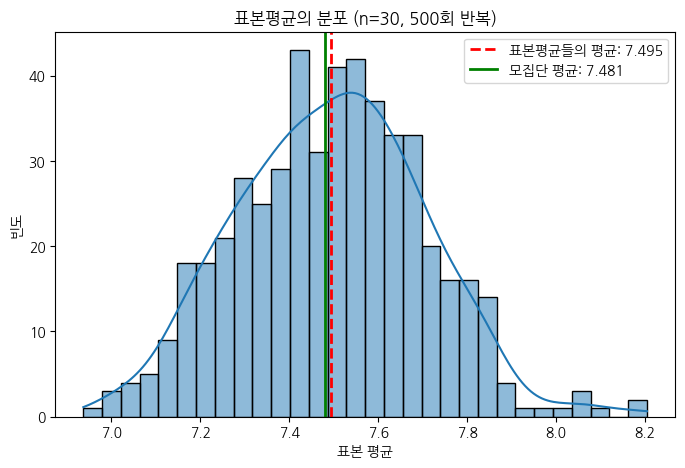

In [25]:
# [문제 1] Q3. 표본 평균들의 분포를 히스토그램으로 그려봅시다. 평균선도 함께 표시해 봅시다.
# 여기에 코드를 작성해주세요.

# 표본평균 분포 히스토그램 + 평균선
plt.figure(figsize=(8, 5))
sns.histplot(sample_means, bins=30, kde=True)

# 표본평균들의 평균선, 모집단 평균선
plt.axvline(np.mean(sample_means), color='red', linestyle='--', linewidth=2,
            label=f'표본평균들의 평균: {np.mean(sample_means):.3f}')
plt.axvline(df_pop['score'].mean(), color='green', linestyle='-', linewidth=2,
            label=f'모집단 평균: {df_pop["score"].mean():.3f}')

plt.title("표본평균의 분포 (n=30, 500회 반복)")
plt.xlabel("표본 평균")
plt.ylabel("빈도")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 평균들은 어떤 값 주변에 많이 분포해 있나요? 이 값은 전체 모집단 평균과 얼마나 비슷한가요?

- 표본을 1번 뽑았을 때와 500번을 반복해서 뽑았을 때, 표본 평균의 분포나 신뢰성에는 어떤 차이가 있나요

- 친구가 다른 표본을 뽑았다면 같은 평균이 나왔을까요? 비슷한 결과가 나왔더라도 완전히 같지 않았다면, 그 이유는 무엇일까요?

- 표본 평균들의 분포는 어떤 모양인가요? 종 모양의 정규분포처럼 보이나요? 그렇다면 왜 그렇게 되는 걸까요?


1. 표본평균은 비편향성이라 평균이 모집단 평균과 거의 일치
- 표본평균들은 약 7.5 부근에 몰려 있음 (95%가 7.11~7.87 구간)
- 표본평균들의 평균 7.495 ≈ 모집단 평균 7.481 (차이 약 0.014)
- 표본평균은 모집단 평균을 체계적으로 과대·과소추정하지 않음 (비편향성)

2. 1번 vs 500번 반복
- 1번: 표본평균 하나뿐이라 얼마나 흔들리는지, 믿을 만한지 판단 불가
- 1번: 운에 따라 극단값(이번 실험에서 약 6.94, 8.20)이 나올 수 있음
- 500번: 표본평균의 분포 확인 가능 → 중심(≈7.5)과 퍼짐(표준오차 ≈ 0.21) 파악
- 반복 횟수가 늘수록 누적 평균이 모집단 평균에 수렴 → 추정의 신뢰성 판단 가능
- 일치성: 표본 크기 n이 커지면 표준오차 σ/√n이 줄어 표본평균이 μ에 수렴
  (500은 반복 횟수이고, 일치성은 n을 키울 때의 성질)

3. 비슷하지만 완전히 같진 않음
- 무작위로 30명만 뽑기 때문에 누가 뽑히느냐에 따라 평균이 달라짐 (표본오차)
- 즉, 표본오차 때문이며, 크기는 표준오차로 나타남
- 오차 크기: 표준오차 σ/√n ≈ 1.18/√30 ≈ 0.216 (실제 0.209)
- 표본평균의 95.8%가 모집단 평균 ±0.4 이내 (표준오차가 작을수록 효율성이 좋음)

4. 정규분포에 가까움 (7.5 중심, 좌우 대칭 종 모양)
- 이유: 중심극한정리(CLT) → 표본 크기가 충분하면(n≥30) 표본평균의 분포는 N(μ, σ/√n)에 근사
- 개별 점수(σ≈1.2)보다 훨씬 좁게 모임(≈0.21): 평균을 내면 극단값이 서로 상쇄되기 때문
- 참고: 이번 모집단은 원래 정규분포에 가까워서 더 깔끔하게 나타남 (random 함수로 데이터 생성)

표본평균들의 평균: 7.495 / 모집단 평균: 7.481
표준오차(실제): 0.209 / 표준오차(이론, σ/√n): 0.216
표본평균 범위: 6.94 ~ 8.20
95% 구간: [7.11 7.87]


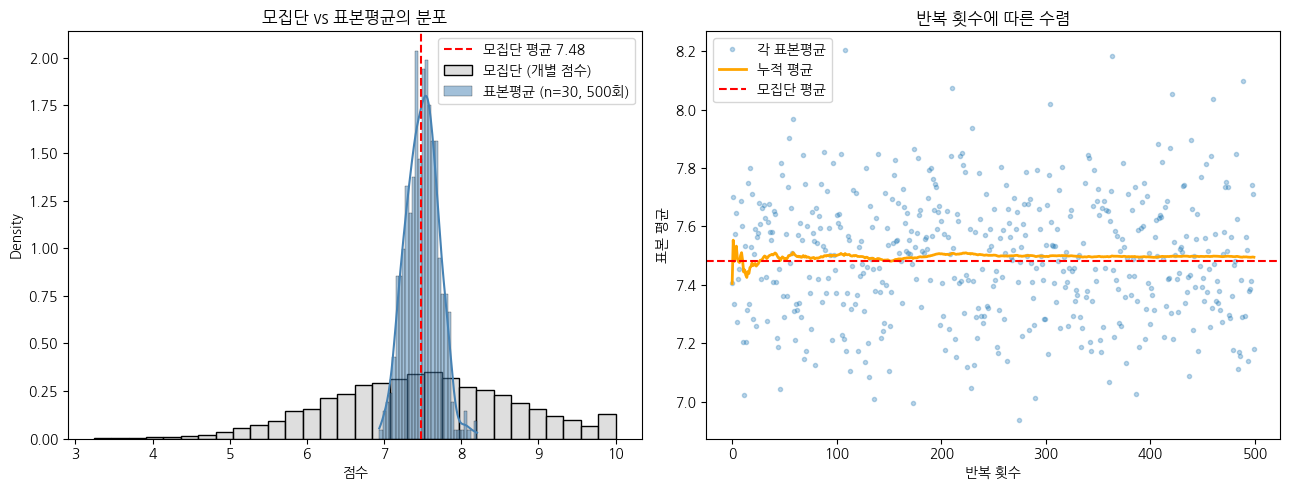

In [26]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

print('''
1. 표본평균은 비편향성이라 평균이 모집단 평균과 거의 일치
- 표본평균들은 약 7.5 부근에 몰려 있음 (95%가 7.11~7.87 구간)
- 표본평균들의 평균 7.495 ≈ 모집단 평균 7.481 (차이 약 0.014)
- 표본평균은 모집단 평균을 체계적으로 과대·과소추정하지 않음 (비편향성)

2. 1번 vs 500번 반복
- 1번: 표본평균 하나뿐이라 얼마나 흔들리는지, 믿을 만한지 판단 불가
- 1번: 운에 따라 극단값(이번 실험에서 약 6.94, 8.20)이 나올 수 있음
- 500번: 표본평균의 분포 확인 가능 → 중심(≈7.5)과 퍼짐(표준오차 ≈ 0.21) 파악
- 반복 횟수가 늘수록 누적 평균이 모집단 평균에 수렴 → 추정의 신뢰성 판단 가능
- 일치성: 표본 크기 n이 커지면 표준오차 σ/√n이 줄어 표본평균이 μ에 수렴
  (500은 반복 횟수이고, 일치성은 n을 키울 때의 성질)

3. 비슷하지만 완전히 같진 않음
- 무작위로 30명만 뽑기 때문에 누가 뽑히느냐에 따라 평균이 달라짐 (표본오차)
- 즉, 표본오차 때문이며, 크기는 표준오차로 나타남
- 오차 크기: 표준오차 σ/√n ≈ 1.18/√30 ≈ 0.216 (실제 0.209)
- 표본평균의 95.8%가 모집단 평균 ±0.4 이내 (표준오차가 작을수록 효율성이 좋음)

4. 정규분포에 가까움 (7.5 중심, 좌우 대칭 종 모양)
- 이유: 중심극한정리(CLT) → 표본 크기가 충분하면(n≥30) 표본평균의 분포는 N(μ, σ/√n)에 근사
- 개별 점수(σ≈1.2)보다 훨씬 좁게 모임(≈0.21): 평균을 내면 극단값이 서로 상쇄되기 때문
- 참고: 이번 모집단은 원래 정규분포에 가까워서 더 깔끔하게 나타남 (random 함수로 데이터 생성)
''')

pop_mean = df_pop['score'].mean()
se_emp = np.std(sample_means, ddof=1)
se_theory = df_pop['score'].std() / np.sqrt(30)

print(f"표본평균들의 평균: {np.mean(sample_means):.3f} / 모집단 평균: {pop_mean:.3f}")
print(f"표준오차(실제): {se_emp:.3f} / 표준오차(이론, σ/√n): {se_theory:.3f}")
print(f"표본평균 범위: {min(sample_means):.2f} ~ {max(sample_means):.2f}")
print(f"95% 구간: {np.percentile(sample_means, [2.5, 97.5]).round(2)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (왼쪽) 모집단 vs 표본평균 분포
sns.histplot(df_pop['score'], bins=30, stat='density', color='lightgray',
             label='모집단 (개별 점수)', ax=axes[0])
sns.histplot(sample_means, bins=30, stat='density', kde=True, color='steelblue',
             label='표본평균 (n=30, 500회)', ax=axes[0])
axes[0].axvline(pop_mean, color='red', linestyle='--', label=f'모집단 평균 {pop_mean:.2f}')
axes[0].set_title("모집단 vs 표본평균의 분포")
axes[0].set_xlabel("점수")
axes[0].legend()

# (오른쪽) 반복 횟수에 따른 누적 평균 수렴
cum_mean = np.cumsum(sample_means) / np.arange(1, len(sample_means) + 1)
axes[1].plot(sample_means, '.', alpha=0.3, label='각 표본평균')
axes[1].plot(cum_mean, color='orange', linewidth=2, label='누적 평균')
axes[1].axhline(pop_mean, color='red', linestyle='--', label='모집단 평균')
axes[1].set_title("반복 횟수에 따른 수렴")
axes[1].set_xlabel("반복 횟수")
axes[1].set_ylabel("표본 평균")
axes[1].legend()

plt.tight_layout()
plt.show()

# 문제 2. 중심극한정리

**📘 문제**

- 현실에서는 모집단의 분포가 정규분포가 아닐 수도 있습니다.

- 예를 들어, 일부 고객은 매우 높은 점수를 주고, 대부분은 낮은 점수를 주는 만족도 분포가 있을 수 있죠. (예: 지수분포)

- 이처럼 원래 분포가 비정규분포여도,
  표본을 여러 번 뽑아 평균을 계산하면, 그 평균들의 분포는 정규분포에 가까워진다는 것을
  **중심극한정리(Central Limit Theorem)**라고 합니다.

- 이번 실습에서는 다양한 크기의 표본을 뽑아 평균을 계산하고,
  그 평균들의 분포가 어떻게 변하는지를 직접 실험해 봅니다.

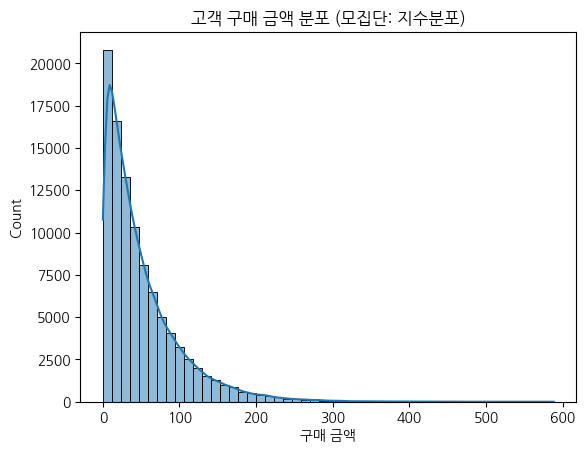

In [27]:
# 지수분포를 따르는 모집단 생성
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포

# 모집단 시각화
sns.histplot(population, bins=50, kde=True)
plt.title("고객 구매 금액 분포 (모집단: 지수분포)")
plt.xlabel("구매 금액")
plt.show()

**📌 아래를 수행해 보세요:**

- 비대칭적인 모집단(지수분포)에서 무작위로 표본을 추출해 평균을 구해봅시다.

- 표본 크기를 바꿔가며, 표본 평균들의 분포가 어떻게 변화하는지 확인해봅시다.

- 히스토그램을 그리고, 분포의 모양을 관찰해봅시다.

- 표본 크기가 커질수록 표본 평균 분포의 모양과 **퍼진 정도(분산)**가 어떻게 변하는지 관찰해봅시다.

In [28]:
# [문제 2] Q1. 모집단에서 표본을 1000번 뽑고, 각 표본의 평균을 구해봅시다.
# 표본 크기 = 5일 때

# 여기에 코드를 작성해주세요.
# 표본 크기 n=5, 1000번 반복 → 표본평균 저장
np.random.seed(2025)
n = 5
n_repeats = 1000

sample_means_5 = [np.random.choice(population, size=n, replace=False).mean()
                  for _ in range(n_repeats)]

print(f"반복 횟수: {len(sample_means_5)}")
print(f"표본평균들의 평균: {np.mean(sample_means_5):.3f}")
print(f"표본평균들의 표준편차(표준오차): {np.std(sample_means_5, ddof=1):.3f}")
print(f"모집단 평균: {population.mean():.3f}")
print(f"이론 표준오차 σ/√n: {population.std() / np.sqrt(n):.3f}")

반복 횟수: 1000
표본평균들의 평균: 49.565
표본평균들의 표준편차(표준오차): 22.795
모집단 평균: 50.233
이론 표준오차 σ/√n: 22.504


In [29]:
# [문제 2] Q2. 위 과정을 표본 크기 30, 100일 때도 반복해봅시다.
# sample_size = 30, 100

# 여기에 코드를 작성해주세요.
np.random.seed(2025)
n_repeats = 1000

sample_means_30 = [np.random.choice(population, size=30, replace=False).mean()
                   for _ in range(n_repeats)]
sample_means_100 = [np.random.choice(population, size=100, replace=False).mean()
                    for _ in range(n_repeats)]

for n, means in [(30, sample_means_30), (100, sample_means_100)]:
    print(f"[n={n}] 표본평균들의 평균: {np.mean(means):.3f} / "
          f"표준오차(실제): {np.std(means, ddof=1):.3f} / "
          f"표준오차(이론): {population.std() / np.sqrt(n):.3f}")

[n=30] 표본평균들의 평균: 49.658 / 표준오차(실제): 9.391 / 표준오차(이론): 9.187
[n=100] 표본평균들의 평균: 50.284 / 표준오차(실제): 5.066 / 표준오차(이론): 5.032


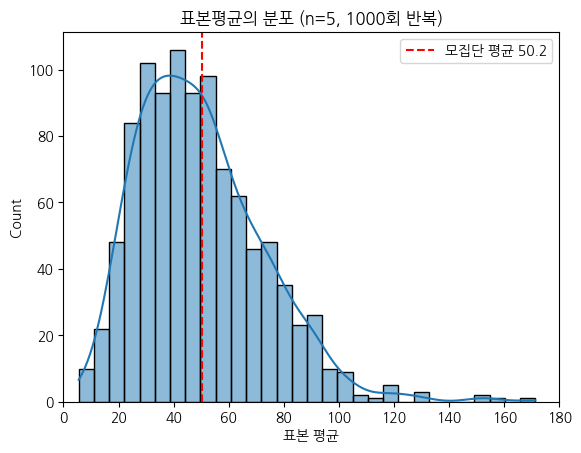

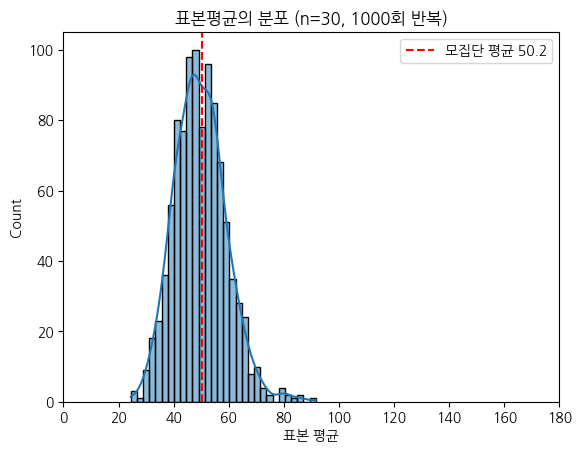

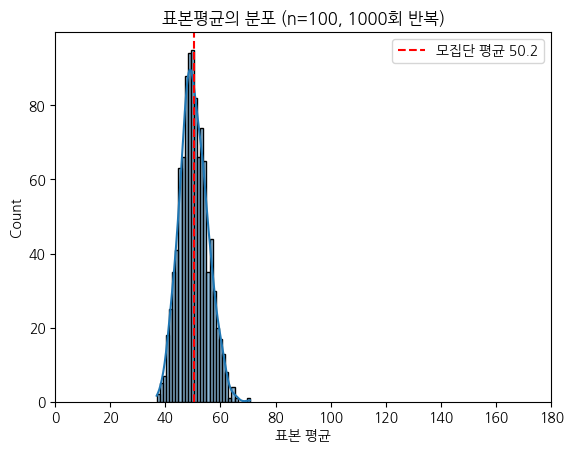

In [30]:
# [문제 2] Q3. 각 표본 크기별로 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 평균선을 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.
# from scipy import stats

def plot_sample_means(means, n, pop_mean):
    sns.histplot(means, bins=30, kde=True)
    plt.axvline(pop_mean, color='red', linestyle='--', label=f'모집단 평균 {pop_mean:.1f}')
    plt.title(f"표본평균의 분포 (n={n}, 1000회 반복)")
    plt.xlabel("표본 평균")
    plt.xlim(0, 180)   # 세 그래프의 x축 범위를 같게 맞춤
    plt.legend()
    plt.show()

pop_mean = population.mean()
plot_sample_means(sample_means_5, 5, pop_mean)
plot_sample_means(sample_means_30, 30, pop_mean)
plot_sample_means(sample_means_100, 100, pop_mean)

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을 때 (예: 5), 평균들의 분포는 어떤 모양인가요?

- 표본 크기가 커질수록 평균 분포의 모양은 어떤 변화를 보이나요?

- 원래 모집단은 비대칭이었는데, 왜 평균들의 분포는 정규분포처럼 바뀌었을까요?

- 이 실험을 통해 중심극한정리를 어떻게 이해하게 되었나요?

- 표본 크기에 따라 **분포의 넓이(흩어짐)**는 어떻게 달라지나요?

In [4]:
# [문제 2] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

print('''
1. 표본 크기가 작을 때(n=5) 평균들의 분포 모양
- 오른쪽으로 꼬리가 긴 비대칭 분포가 남아 있음 (왜도 약 0.96)
- 모집단(왜도 2.00)보다는 덜 치우쳤지만 정규분포로 보기는 어려움
- 평균(49.56)이 중앙값(46.62)보다 큰 것도 오른쪽 꼬리의 흔적
- 값의 범위도 넓음 (약 5.6 ~ 171.3)

2. 표본 크기가 커질수록 평균 분포 모양의 변화
- n=5 → 30 → 100으로 갈수록 왜도가 줄어듦 (0.96 → 0.47 → 0.26)
- 오른쪽 꼬리가 짧아지고 좌우 대칭의 종 모양에 가까워짐
- n=30에서도 약간 치우친 흔적이 있고, n=100에서 거의 대칭

3. 모집단은 비대칭인데 평균들의 분포는 왜 정규분포처럼 바뀌었나
- 표본평균은 여러 값을 더해서 n으로 나눈 값이라, 표본 안에 큰 값과 작은 값이 섞여 서로 상쇄됨
- 극단적으로 큰 값(꼬리)이 표본에 들어가도 나머지 값들이 평균을 끌어내림
- 표본이 클수록 상쇄가 잘 일어나서 평균이 한쪽으로 크게 치우치기 어려워짐
- 이것이 중심극한정리: >>모집단 모양과 상관없이 n이 충분히 크면 표본평균의 분포는 정규분포에 근사<<

4. 이 실험을 통해 이해한 중심극한정리
- 모집단이 정규분포가 아니어도(지수분포, 왜도 2.00) 표본평균의 분포는 정규분포에 가까워짐
- 표본평균들의 평균은 n과 상관없이 모집단 평균(50.23) 근처 (비편향성)
- n이 커질수록 정규분포에 더 가까워지고 퍼짐은 줄어듦
- "n≥30이면 충분"은 어림 기준이고, 모집단이 많이 치우칠수록 더 큰 n이 필요함

5. 표본 크기에 따른 분포의 넓이(흩어짐)
- 표준오차가 n이 커질수록 줄어듦: n=5 → 22.79, n=30 → 9.39, n=100 → 5.07
- 이론값 σ/√n과 거의 일치 (22.50, 9.19, 5.03)
- n이 4배 늘면 퍼짐은 절반 (σ/√n 관계): 5 → 100은 20배 증가, 표준오차는 약 4.5배 감소
- 표본평균이 모집단 평균에서 덜 벗어나므로 추정이 더 정확해짐
''')

# 근거 수치
pop_mean = population.mean()
all_means = {5: sample_means_5, 30: sample_means_30, 100: sample_means_100}

print(f"모집단 평균: {pop_mean:.2f} / 모집단 왜도: {pd.Series(population).skew():.2f}")
for n, means in all_means.items():
    s = pd.Series(means)
    print(f"[n={n:>3}] 평균: {s.mean():.2f} / 중앙값: {s.median():.2f} / "
          f"표준오차(실제): {s.std():.2f} / 표준오차(이론): {population.std() / np.sqrt(n):.2f} / "
          f"왜도: {s.skew():.2f}")


1. 표본 크기가 작을 때(n=5) 평균들의 분포 모양
- 오른쪽으로 꼬리가 긴 비대칭 분포가 남아 있음 (왜도 약 0.96)
- 모집단(왜도 2.00)보다는 덜 치우쳤지만 정규분포로 보기는 어려움
- 평균(49.56)이 중앙값(46.62)보다 큰 것도 오른쪽 꼬리의 흔적
- 값의 범위도 넓음 (약 5.6 ~ 171.3)

2. 표본 크기가 커질수록 평균 분포 모양의 변화
- n=5 → 30 → 100으로 갈수록 왜도가 줄어듦 (0.96 → 0.47 → 0.26)
- 오른쪽 꼬리가 짧아지고 좌우 대칭의 종 모양에 가까워짐
- n=30에서도 약간 치우친 흔적이 있고, n=100에서 거의 대칭

3. 모집단은 비대칭인데 평균들의 분포는 왜 정규분포처럼 바뀌었나
- 표본평균은 여러 값을 더해서 n으로 나눈 값이라, 표본 안에 큰 값과 작은 값이 섞여 서로 상쇄됨
- 극단적으로 큰 값(꼬리)이 표본에 들어가도 나머지 값들이 평균을 끌어내림
- 표본이 클수록 상쇄가 잘 일어나서 평균이 한쪽으로 크게 치우치기 어려워짐
- 이것이 중심극한정리: >>모집단 모양과 상관없이 n이 충분히 크면 표본평균의 분포는 정규분포에 근사<<

4. 이 실험을 통해 이해한 중심극한정리
- 모집단이 정규분포가 아니어도(지수분포, 왜도 2.00) 표본평균의 분포는 정규분포에 가까워짐
- 표본평균들의 평균은 n과 상관없이 모집단 평균(50.23) 근처 (비편향성)
- n이 커질수록 정규분포에 더 가까워지고 퍼짐은 줄어듦
- "n≥30이면 충분"은 어림 기준이고, 모집단이 많이 치우칠수록 더 큰 n이 필요함

5. 표본 크기에 따른 분포의 넓이(흩어짐)
- 표준오차가 n이 커질수록 줄어듦: n=5 → 22.79, n=30 → 9.39, n=100 → 5.07
- 이론값 σ/√n과 거의 일치 (22.50, 9.19, 5.03)
- n이 4배 늘면 퍼짐은 절반 (σ/√n 관계): 5 → 100은 20배 증가, 표준오차는 약 4.5배 감소
- 표본평균이 모집단 평균에서 덜 벗어나므로 추정이 더 정확해

# 문제 3. 표준오차

**📘 문제**

- 앞선 실습에서 우리는 **표본 크기(n)가 커질수록 표본 평균들의 분포가 더 좁아진다**는 것을 확인했습니다.
- 이처럼 표본 평균들이 얼마나 흩어져 있는지(분포의 퍼진 정도)를 나타내는 값을 **표준오차(Standard Error, SE)**라고 부릅니다.
- 표준오차는 **표본 평균들의 표준편차**와 같은 의미이며, 이는 우리가 뽑은 표본 평균이 실제 모평균과 평균적으로 얼마나 떨어져 있을지를 나타내는 **'예상 오차의 크기'**입니다.

- 통계학적으로 이 표준오차는 **`SE = σ / √n`** (모집단 표준편차 / 표본 크기의 제곱근) 이라는 공식으로 계산할 수 있습니다.
- 이 공식은 **표본 크기(n)가 커질수록 표준오차(SE)가 작아진다**는 것을 명확히 보여줍니다.

- 이번 실습에서는 여러 크기의 표본을 뽑아, 시뮬레이션을 통해 얻은 **표본 평균들의 표준편차(실험값)**가 공식으로 계산한 **표준오차(이론값)**와 얼마나 일치하는지 직접 확인해봅니다.

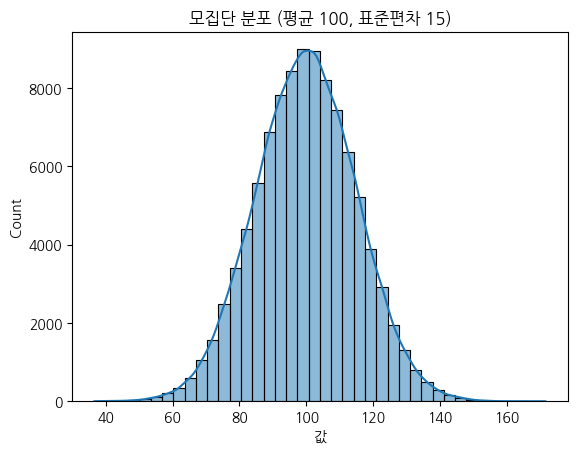

In [5]:
# 모집단 생성 (평균 100, 표준편차 15)
np.random.seed(2025)
population = np.random.normal(loc=100, scale=15, size=100000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 100, 표준편차 15)")
plt.xlabel("값")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 여러 크기의 표본(10, 30, 100, 500)을 각각 1000번 뽑고, 그 평균들을 구한 뒤, **표본 평균들의 표준편차(=실험적 표준오차)**를 계산해봅시다.

- 이 결과를 이론적인 표준오차 공식과 비교하는 표를 만들고, 시각화해봅시다.

In [6]:
# [문제 3] Q1. 표본 크기 10, 30, 100, 500에 대해 각각 1000번 표본을 뽑고, 평균을 구해봅시다.
# 각 표본 평균 분포의 표준편차를 계산해봅시다.
# 결과를 리스트에 저장하고, 표로 정리해봅시다.

# 여기에 코드를 작성해주세요.
np.random.seed(2025)   # 반복문 밖에서 한 번만 설정
sample_sizes = [10, 30, 100, 500]
n_repeats = 1000

sample_means_dict = {}   # {표본 크기: 표본평균 리스트}

for n in sample_sizes:
    means = []
    for _ in range(n_repeats):
        means.append(np.random.choice(population, size=n, replace=False).mean())
    sample_means_dict[n] = means
    print(f"[n={n:>3}] 반복 {len(means)}회 / 표본평균들의 평균: {np.mean(means):.3f} / "
          f"표본평균들의 표준편차(실험적 SE): {np.std(means, ddof=1):.3f}")

[n= 10] 반복 1000회 / 표본평균들의 평균: 100.098 / 표본평균들의 표준편차(실험적 SE): 4.561
[n= 30] 반복 1000회 / 표본평균들의 평균: 99.973 / 표본평균들의 표준편차(실험적 SE): 2.748
[n=100] 반복 1000회 / 표본평균들의 평균: 100.030 / 표본평균들의 표준편차(실험적 SE): 1.493
[n=500] 반복 1000회 / 표본평균들의 평균: 99.953 / 표본평균들의 표준편차(실험적 SE): 0.654


In [7]:
# [문제 3] Q2. 이론적인 표준오차와 비교해봅시다.
# [공식] 표준오차(SE) = 모집단 표준편차 / √표본크기

# 여기에 코드를 작성해주세요.
pop_std = population.std()   # 모집단 표준편차 σ

result = []
for n in sample_sizes:
    se_exp = np.std(sample_means_dict[n], ddof=1)   # 실험적 표준오차
    se_theory = pop_std / np.sqrt(n)                # 이론적 표준오차 σ/√n
    result.append({
        '표본 크기(n)': n,
        '실험 SE': se_exp,
        '이론 SE': se_theory,
        '차이': se_exp - se_theory,
        '오차율(%)': abs(se_exp - se_theory) / se_theory * 100
    })

df_se = pd.DataFrame(result).round(3)
print(f"모집단 표준편차 σ: {pop_std:.3f}")
df_se

모집단 표준편차 σ: 15.033
   표본 크기(n)  실험 SE  이론 SE   차이  오차율(%)
0            10    4.561    4.754 -0.193      4.059
1            30    2.748    2.745  0.003      0.117
2           100    1.493    1.503 -0.010      0.682
3           500    0.654    0.672 -0.019      2.790


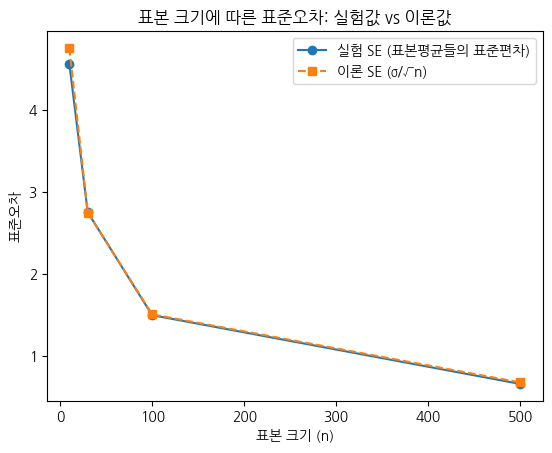

In [8]:
# [문제 3] Q3. 실험값과 이론값을 시각화해봅시다.
# 표본 크기를 x축, 표준오차를 y축으로 한 꺾은선 그래프를 그려봅시다.

# 여기에 코드를 작성해주세요.
plt.plot(df_se['표본 크기(n)'], df_se['실험 SE'], 'o-', label='실험 SE (표본평균들의 표준편차)')
plt.plot(df_se['표본 크기(n)'], df_se['이론 SE'], 's--', label='이론 SE (σ/√n)')
plt.title("표본 크기에 따른 표준오차: 실험값 vs 이론값")
plt.xlabel("표본 크기 (n)")
plt.ylabel("표준오차")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을수록, 표본 평균의 분포는 어떤 모양인가요? 넓게 퍼져 있나요?

- 표본 크기가 커질수록, 평균 분포는 어떻게 변하나요?

- 실험값과 이론값(공식 계산값)은 얼마나 비슷한가요?

- 왜 표본 크기가 커질수록 표준오차는 작아질까요?

In [9]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

print('''
1. 표본 크기가 작을수록 표본 평균의 분포
- 표본 평균의 분포가 넓게 퍼져 있음 (표준오차가 큼)
- n=10일 때 실험 SE 4.561로, n=500의 0.654보다 약 7배 넓음
- 표본이 적으면 어떤 사람이 뽑히느냐에 따라 평균이 크게 흔들리기 때문
- (이번 모집단은 정규분포라서 n이 작아도 종 모양은 유지, 달라지는 건 퍼짐의 정도)

2. 표본 크기가 커질수록 평균 분포의 변화
- 분포가 모집단 평균(≈100) 주변으로 점점 좁게 모임
- 실험 SE: n=10 → 4.561, n=30 → 2.748, n=100 → 1.493, n=500 → 0.654
- n이 커질수록 표본 평균이 모평균에서 덜 벗어남 → 추정이 더 정확해짐
- 중심은 n과 상관없이 모집단 평균 근처 (비편향성)

3. 실험값과 이론값의 유사도
- 매우 비슷함 (오차율 0.12% ~ 4.06%)
- n=10: 4.561 vs 4.754 / n=30: 2.748 vs 2.745 / n=100: 1.493 vs 1.503 / n=500: 0.654 vs 0.672
- 실험 SE가 이론 SE(σ/√n)와 거의 일치 → 공식이 실제 시뮬레이션과 잘 맞음
- 오차율이 n에 따라 일정하게 줄지는 않음: 실험 SE 자체가 1000번 반복에서 나온 값이라 무작위로 조금 흔들리기 때문
- 반복 횟수를 늘리면 실험값이 이론값에 더 가까워질 것

4. 왜 표본 크기가 커질수록 표준오차가 작아질까
- 표본 평균은 여러 값을 더해 n으로 나눈 값이라, 큰 값과 작은 값이 서로 상쇄됨
- n이 커질수록 상쇄가 더 잘 일어나 평균이 한쪽으로 크게 치우치기 어려움
- 수식: SE = σ/√n → 개별 값의 흩어짐(σ)은 그대로이고 √n이 커지는 만큼 SE가 줄어듦
- n이 4배가 되면 SE는 절반 (1/√4), 정확도를 2배 높이려면 표본을 4배로 늘려야 함
- n이 무한히 커지면 SE → 0, 표본평균이 모평균에 수렴 (일치성)
''')

# 근거 수치
print(f"모집단 평균: {population.mean():.3f} / 모집단 표준편차 σ: {population.std():.3f}")
df_se


1. 표본 크기가 작을수록 표본 평균의 분포
- 표본 평균의 분포가 넓게 퍼져 있음 (표준오차가 큼)
- n=10일 때 실험 SE 4.561로, n=500의 0.654보다 약 7배 넓음
- 표본이 적으면 어떤 사람이 뽑히느냐에 따라 평균이 크게 흔들리기 때문
- (이번 모집단은 정규분포라서 n이 작아도 종 모양은 유지, 달라지는 건 퍼짐의 정도)

2. 표본 크기가 커질수록 평균 분포의 변화
- 분포가 모집단 평균(≈100) 주변으로 점점 좁게 모임
- 실험 SE: n=10 → 4.561, n=30 → 2.748, n=100 → 1.493, n=500 → 0.654
- n이 커질수록 표본 평균이 모평균에서 덜 벗어남 → 추정이 더 정확해짐
- 중심은 n과 상관없이 모집단 평균 근처 (비편향성)

3. 실험값과 이론값의 유사도
- 매우 비슷함 (오차율 0.12% ~ 4.06%)
- n=10: 4.561 vs 4.754 / n=30: 2.748 vs 2.745 / n=100: 1.493 vs 1.503 / n=500: 0.654 vs 0.672
- 실험 SE가 이론 SE(σ/√n)와 거의 일치 → 공식이 실제 시뮬레이션과 잘 맞음
- 오차율이 n에 따라 일정하게 줄지는 않음: 실험 SE 자체가 1000번 반복에서 나온 값이라 무작위로 조금 흔들리기 때문
- 반복 횟수를 늘리면 실험값이 이론값에 더 가까워질 것

4. 왜 표본 크기가 커질수록 표준오차가 작아질까
- 표본 평균은 여러 값을 더해 n으로 나눈 값이라, 큰 값과 작은 값이 서로 상쇄됨
- n이 커질수록 상쇄가 더 잘 일어나 평균이 한쪽으로 크게 치우치기 어려움
- 수식: SE = σ/√n → 개별 값의 흩어짐(σ)은 그대로이고 √n이 커지는 만큼 SE가 줄어듦
- n이 4배가 되면 SE는 절반 (1/√4), 정확도를 2배 높이려면 표본을 4배로 늘려야 함
- n이 무한히 커지면 SE → 0, 표본평균이 모평균에 수렴 (일치성)

모집단 평균: 99.945 / 모집단 표준편차 σ: 15.033
   표본

# 문제 4. 신뢰구간 계산과 해석

**📘 문제**

- 표본 평균은 모집단 평균을 추정하는 좋은 점 추정(Point Estimation) 값이지만, 표본오차 때문에 정확히 일치하지는 않습니다.

- 그래서 우리는 "모집단 평균이 아마 이 범위 안에 있을 것이다"라고 **구간으로 추정(Interval Estimation)**하는 것이 더 합리적입니다. 이때 사용하는 개념이 바로 **신뢰구간(Confidence Interval)**입니다.

- 신뢰구간은 표본평균 ± 오차범위 형태로 계산되며, 이 오차범위는 신뢰수준(예: 95%, 99%)과 표본오차에 의해 결정됩니다.

- 이번 실습에서는 **모집단 표준편차(σ)를 알 때(z-분포)**와 **모를 때(t-분포)**의 신뢰구간을 각각 계산해보고, 신뢰수준에 따라 구간의 폭이 어떻게 변하는지 확인해봅니다.

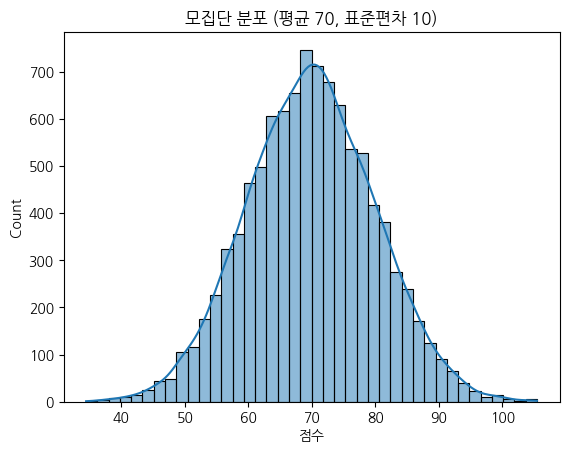

In [10]:
# 모집단 생성
np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 70, 표준편차 10)")
plt.xlabel("점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 30명을 무작위로 뽑아 평균, 표준편차, 표준오차를 계산해보세요.

- 95% 신뢰구간을 z-분포와 t-분포를 각각 사용해서 계산해보세요.

- 신뢰수준을 바꿨을 때(90%, 99%) 신뢰구간이 어떻게 변하는지 확인해보세요.

In [11]:
# [문제 4] Q1. 모집단에서 표본 30명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 표준오차도 함께 계산해보세요.

# 여기에 코드를 작성해주세요.

np.random.seed(2025)
n = 30
sample = np.random.choice(population, size=n, replace=False)

sample_mean = sample.mean()
sample_std = sample.std(ddof=1)          # 표본표준편차 (ddof=1)
sample_se = sample_std / np.sqrt(n)      # 표본오차 추정치 s/√n

print(f"표본 평균: {sample_mean:.3f}")
print(f"표본 표준편차(s): {sample_std:.3f}")
print(f"표준오차(s/√n): {sample_se:.3f}")
print(f"모집단 평균: {population.mean():.3f} / 모집단 표준편차: {population.std():.3f}")

표본 평균: 69.206
표본 표준편차(s): 7.875
표준오차(s/√n): 1.438
모집단 평균: 69.904 / 모집단 표준편차: 10.005


**ddof=1 (n−1로 나누는 이유) 메모**

**핵심 수식**
- Σ(x − μ)² = Σ(x − x̄)² + n(x̄ − μ)²
- 왼쪽: 우리가 알고 싶은 진짜 퍼짐 (평균적으로 nσ²)
- Σ(x − x̄)²: 우리가 계산할 수 있는 값이고, 뒤 항만큼 **작음**

**n−1이 나오는 과정**
- E[n(x̄ − μ)²] = n × Var(x̄) = n × σ²/n = **σ²**
- 그래서 E[Σ(x − x̄)²] = nσ² − σ² = **(n−1)σ²**
- n으로 나누면 평균이 (n−1)σ²/n으로 과소추정되고, n−1로 나누면 σ²가 돼서 불편추정량이 됨

**왜 작게 나오나**
- x̄는 그 표본 데이터에 가장 가깝게 맞춰진 값이라, 표본이 x̄ 주변에 μ 주변보다 촘촘히 모임
- 그래서 x̄ 기준 편차의 제곱합은 μ 기준보다 항상 같거나 작음

**자유도 n−1 (감 잡는 용도)**
- 평균을 계산하면 편차(x − x̄)들의 합이 항상 0이라는 제약이 생김
- 편차 n개 중 독립적인 정보는 n−1개

**숫자 확인** (모분산 100.4, n=5, 2만 번 반복)
- n으로 나눔: 79.7 (과소추정)
- n−1로 나눔: 99.7 (모분산에 근접)
- n이 커질수록 차이가 줄어듦 (n=5에서 가장 크게 드러남)

**코드 규칙**
- 표본으로 모집단 퍼짐 추정: `ddof=1` (n−1)
- 모집단 전체 데이터가 있을 때: `ddof=0` (n)
- `np.std()` 기본값은 0, pandas `.std()` 기본값은 1
- `np.std(pandas_series)`도 ddof=0이라, 표본에서는 `ddof=1`을 직접 명시하는 게 안전

In [12]:
# [문제 4] Q2. 모집단의 표준편차를 알고 있다고 가정하고, z-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

# 여기에 코드를 작성해주세요.
from scipy import stats

pop_std = population.std()                # σ를 알고 있다고 가정
se_z = pop_std / np.sqrt(n)               # σ/√n
z_crit = stats.norm.ppf(0.975)            # 95% → 양쪽 2.5%씩 → 상위 97.5% 지점

z_lower = sample_mean - z_crit * se_z
z_upper = sample_mean + z_crit * se_z

print(f"z 임계값: {z_crit:.3f}")
print(f"95% 신뢰구간 (z): [{z_lower:.3f}, {z_upper:.3f}] / 폭: {z_upper - z_lower:.3f}")
print(f"모집단 평균 {population.mean():.3f} 포함 여부: {z_lower <= population.mean() <= z_upper}")

z 임계값: 1.960
95% 신뢰구간 (z): [65.626, 72.786] / 폭: 7.160
모집단 평균 69.904 포함 여부: True


In [13]:
# [문제 4] Q3. 모집단의 표준편차를 모른다고 가정하고, 표본 표준편차와 t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

# 여기에 코드를 작성해주세요.
t_crit = stats.t.ppf(0.975, df=n - 1)     # 자유도 = n-1 = 29

t_lower = sample_mean - t_crit * sample_se
t_upper = sample_mean + t_crit * sample_se

print(f"t 임계값(df={n-1}): {t_crit:.3f}")
print(f"95% 신뢰구간 (t): [{t_lower:.3f}, {t_upper:.3f}] / 폭: {t_upper - t_lower:.3f}")
print(f"모집단 평균 {population.mean():.3f} 포함 여부: {t_lower <= population.mean() <= t_upper}")

t 임계값(df=29): 2.045
95% 신뢰구간 (t): [66.265, 72.147] / 폭: 5.882
모집단 평균 69.904 포함 여부: True


In [14]:
# [문제 4] Q4. 신뢰수준을 90%, 99%로 바꿔가며 신뢰구간을 계산해보고, 그 폭을 비교해봅시다.

# 여기에 코드를 작성해주세요.
result = []
for conf in [0.90, 0.95, 0.99]:
    alpha = 1 - conf
    z_c = stats.norm.ppf(1 - alpha / 2)
    t_c = stats.t.ppf(1 - alpha / 2, df=n - 1)

    z_low, z_up = sample_mean - z_c * se_z, sample_mean + z_c * se_z
    t_low, t_up = sample_mean - t_c * sample_se, sample_mean + t_c * sample_se

    result.append({
        '신뢰수준': f"{conf*100:.0f}%",
        'z 구간': f"[{z_low:.2f}, {z_up:.2f}]", 'z 폭': z_up - z_low,
        't 구간': f"[{t_low:.2f}, {t_up:.2f}]", 't 폭': t_up - t_low
    })

df_ci = pd.DataFrame(result).round(2)
df_ci

  신뢰수준          z 구간  z 폭          t 구간  t 폭
0      90%  [66.20, 72.21]  6.01  [66.76, 71.65]  4.89
1      95%  [65.63, 72.79]  7.16  [66.27, 72.15]  5.88
2      99%  [64.50, 73.91]  9.41  [65.24, 73.17]  7.93


In [31]:
print('''
t 구간 vs z 구간 폭 
- 폭 = 2 × 임계값 × 표준오차
- z: SE = σ/√n (σ 고정) → 폭 항상 7.16
- t: SE = s/√n (s가 표본마다 변함) → 폭도 변함
- t 폭 / z 폭 = (2.045/1.960) × (s/σ) = 1.044 × (s/σ)
- s > 약 9.59(σ의 0.958배)면 t가 더 넓고, 그보다 작으면 t가 더 좁음
- 이번 표본은 s=7.875로 작게 나와서(하위 약 5%) t가 좁게 나온 우연
- 2만 번 시뮬레이션: t가 더 넓은 경우 약 60%, 평균적으로 t가 약간 더 넓음
- 신뢰도는 z 95.1%, t 95.0%로 둘 다 약 95% → 폭만 보고 우열을 판단하면 안 됨
- σ를 모르면 t를 쓰는 게 맞음. t 임계값이 s의 불확실성을 반영해서 z보다 큼
''')


t 구간 vs z 구간 폭 
- 폭 = 2 × 임계값 × 표준오차
- z: SE = σ/√n (σ 고정) → 폭 항상 7.16
- t: SE = s/√n (s가 표본마다 변함) → 폭도 변함
- t 폭 / z 폭 = (2.045/1.960) × (s/σ) = 1.044 × (s/σ)
- s > 약 9.59(σ의 0.958배)면 t가 더 넓고, 그보다 작으면 t가 더 좁음
- 이번 표본은 s=7.875로 작게 나와서(하위 약 5%) t가 좁게 나온 우연
- 2만 번 시뮬레이션: t가 더 넓은 경우 약 60%, 평균적으로 t가 약간 더 넓음
- 신뢰도는 z 95.1%, t 95.0%로 둘 다 약 95% → 폭만 보고 우열을 판단하면 안 됨
- σ를 모르면 t를 쓰는 게 맞음. t 임계값이 s의 불확실성을 반영해서 z보다 큼



**🧠 데이터를 어떻게 읽을까요?**

- z-분포와 t-분포를 사용한 신뢰구간은 얼마나 차이가 있나요?

- 신뢰수준이 높아질수록 신뢰구간의 폭은 어떻게 변하나요? 왜 그럴까요?

- 신뢰구간이 넓다는 건 좋은 걸까요? 나쁜 걸까요?

- 이 데이터가 실제 고객 만족도라면, 신뢰구간 정보를 마케팅 전략에 어떻게 활용할 수 있을까요?

In [15]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

print('''
1. z-분포와 t-분포를 사용한 신뢰구간의 차이
- 같은 95%에서 z 구간 [65.63, 72.79](폭 7.16), t 구간 [66.27, 72.15](폭 5.88)로 큰 차이는 없고 중심(표본평균 69.21)이 같음
- t 임계값(2.045)이 z 임계값(1.960)보다 커서, 같은 표준오차라면 t 구간이 더 넓어짐
- 이번 표본에서는 t 구간이 오히려 더 좁게 나옴: 표본 표준편차 s(7.88)가 모표준편차 σ(10.01)보다 작아서 표준오차가 줄었기 때문
- 표본이 달라지면 s가 σ보다 크게 나와 t 구간이 더 넓어질 수도 있음 (t는 σ를 모르는 불확실성을 반영한 방식)
- n이 커지면 t 분포가 z 분포에 가까워져 두 구간의 차이가 줄어듦
- 두 구간 모두 모집단 평균(69.90)을 포함

2. 신뢰수준이 높아질수록 신뢰구간의 폭과 그 이유
- 신뢰수준이 높아질수록 구간이 넓어짐: z 폭 6.01(90%) → 7.16(95%) → 9.41(99%), t 폭 4.89 → 5.88 → 7.93
- 이유: 구간 = 표본평균 ± 임계값 × 표준오차인데, 신뢰수준이 높을수록 임계값이 커짐 (z: 1.645 → 1.960 → 2.576)
- 모평균을 놓치지 않을 확률을 높이려면 더 넓은 그물이 필요함
- 증가폭도 커짐: 90→95%는 +1.15, 95→99%는 +2.25 (z 기준) → 확신을 높일수록 폭이 점점 더 빠르게 늘어남

3. 신뢰구간이 넓다는 것은 좋은가, 나쁜가
- 좋다/나쁘다보다 정밀도와 확신 사이의 trade-off
- 넓은 구간: 모평균을 포함할 가능성(확신)은 높지만, 추정이 덜 구체적이라 정보량이 적음
- 좁은 구간: 정밀하지만 모평균을 놓칠 위험이 큼
- 확신을 유지하면서 구간을 좁히는 방법은 표본 크기 n을 늘리는 것 (표준오차 = s/√n이 줄어듦)
- 예: 구간 폭 [64.50, 73.91](99%, z)은 약 9점 범위라서 "평균 만족도가 70점 근처"라는 정도만 말할 수 있음

4. 실제 고객 만족도라면 마케팅 전략에 어떻게 활용할까
- 현재 수준 파악: 표본평균 69.2점이지만 점 추정값이 아니라 "평균 만족도는 약 66~72점 범위(95% 신뢰구간)"로 보고해야 함
- 목표 설정/성과 평가: 개선 캠페인 전후의 구간을 비교해 구간이 겹치지 않으면 의미 있는 변화로 판단 가능
- 의사결정 기준: 구간 하한(약 66점)이 기준선(예: 65점) 이상이면 안정적, 걸쳐 있으면 표본을 더 모아 판단
- 표본 설계: 더 정밀한 추정이 필요하면 설문 응답자 수를 늘림
- 주의: 신뢰구간은 "평균"의 범위이지 개별 고객 점수의 범위가 아님 (개별 점수는 표준편차 약 10으로 훨씬 넓게 퍼짐)
- 해석 주의: "95% 신뢰구간 = 모평균이 이 구간에 있을 확률 95%"가 아니라, "같은 방법으로 반복해서 구간을 만들면 약 95%가 모평균을 포함한다"는 뜻
''')

# 근거 수치
print(f"표본평균: {sample_mean:.2f} / 표본 표준편차 s: {sample_std:.2f} / 모표준편차 σ: {pop_std:.2f}")
print(f"95% t 구간: [{t_lower:.2f}, {t_upper:.2f}]")
df_ci


1. z-분포와 t-분포를 사용한 신뢰구간의 차이
- 같은 95%에서 z 구간 [65.63, 72.79](폭 7.16), t 구간 [66.27, 72.15](폭 5.88)로 큰 차이는 없고 중심(표본평균 69.21)이 같음
- t 임계값(2.045)이 z 임계값(1.960)보다 커서, 같은 표준오차라면 t 구간이 더 넓어짐
- 이번 표본에서는 t 구간이 오히려 더 좁게 나옴: 표본 표준편차 s(7.88)가 모표준편차 σ(10.01)보다 작아서 표준오차가 줄었기 때문
- 표본이 달라지면 s가 σ보다 크게 나와 t 구간이 더 넓어질 수도 있음 (t는 σ를 모르는 불확실성을 반영한 방식)
- n이 커지면 t 분포가 z 분포에 가까워져 두 구간의 차이가 줄어듦
- 두 구간 모두 모집단 평균(69.90)을 포함

2. 신뢰수준이 높아질수록 신뢰구간의 폭과 그 이유
- 신뢰수준이 높아질수록 구간이 넓어짐: z 폭 6.01(90%) → 7.16(95%) → 9.41(99%), t 폭 4.89 → 5.88 → 7.93
- 이유: 구간 = 표본평균 ± 임계값 × 표준오차인데, 신뢰수준이 높을수록 임계값이 커짐 (z: 1.645 → 1.960 → 2.576)
- 모평균을 놓치지 않을 확률을 높이려면 더 넓은 그물이 필요함
- 증가폭도 커짐: 90→95%는 +1.15, 95→99%는 +2.25 (z 기준) → 확신을 높일수록 폭이 점점 더 빠르게 늘어남

3. 신뢰구간이 넓다는 것은 좋은가, 나쁜가
- 좋다/나쁘다보다 정밀도와 확신 사이의 trade-off
- 넓은 구간: 모평균을 포함할 가능성(확신)은 높지만, 추정이 덜 구체적이라 정보량이 적음
- 좁은 구간: 정밀하지만 모평균을 놓칠 위험이 큼
- 확신을 유지하면서 구간을 좁히는 방법은 표본 크기 n을 늘리는 것 (표준오차 = s/√n이 줄어듦)
- 예: 구간 폭 [64.50, 73.91](99%, z)은 약 9점 범위라서 "평균 만족도가 70점 근처"라는 정도만 말할 수 있음

4. 실제 고객 만족도라면 마케팅 전략에 어

# 문제 5. 미니 프로젝트 - 고객 만족도 신뢰구간 추정

**📘 문제**

- 전체 고객 10,000명을 대상으로 만족도 조사를 하는 것은 시간과 비용이 많이 듭니다.
- 그래서 우리는 무작위로 일부 고객만 조사하여, 전체 고객의 평균 만족도를 추정하려 합니다.

- 이 프로젝트에서는 실제와 같은 상황을 가정하여, 표본을 뽑고 신뢰구간을 계산한 뒤, 이 결과를 바탕으로 마케팅 전략에 어떻게 활용할 수 있을지까지 생각해보는 실습을 진행합니다.

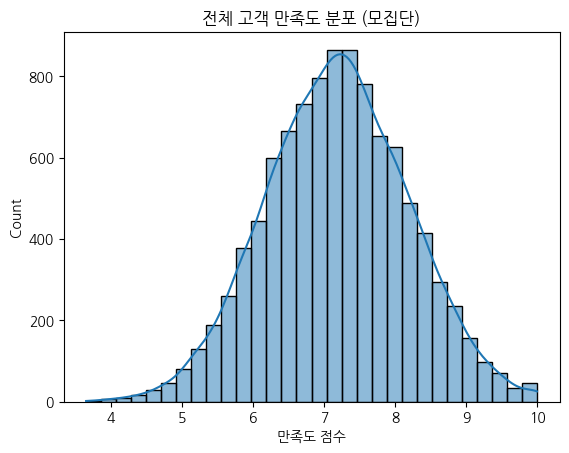

In [16]:
# 모집단 생성 (고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.2, scale=1.0, size=10000)
population = np.clip(population, 1, 10)

# 모집단 시각화
sns.histplot(population, bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단을 생성하고, 거기서 표본을 40명 뽑아 평균을 계산해봅시다.

- 표본 평균과 표준편차를 바탕으로 95% 신뢰구간을 계산해봅시다.

- 히스토그램을 그리고 신뢰구간을 시각화해봅시다.

- 이 결과를 어떻게 해석하고, 마케팅 전략에 활용할 수 있을지 생각해봅시다.

In [17]:
# [문제 5] Q1. 모집단에서 표본 40명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 여기에 코드를 작성해주세요.

np.random.seed(2025)
n = 40
sample = np.random.choice(population, size=n, replace=False)

sample_mean = sample.mean()
sample_std = sample.std(ddof=1)   # 표본표준편차 (ddof=1)

print(f"표본 크기: {n}")
print(f"표본 평균: {sample_mean:.3f}")
print(f"표본 표준편차: {sample_std:.3f}")
print(f"모집단 평균(참고): {population.mean():.3f}")

표본 크기: 40
표본 평균: 7.226
표본 표준편차: 0.897
모집단 평균(참고): 7.190


In [18]:
# [문제 5] Q2. 표준오차(SE)를 구하고, t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
# 여기에 코드를 작성해주세요.
from scipy import stats

se = sample_std / np.sqrt(n)                  # 표준오차 s/√n
t_crit = stats.t.ppf(0.975, df=n - 1)         # 자유도 39
margin = t_crit * se                          # 오차범위

ci_lower = sample_mean - margin
ci_upper = sample_mean + margin

print(f"표준오차(SE): {se:.3f}")
print(f"t 임계값(df={n-1}): {t_crit:.3f}")
print(f"오차범위: ±{margin:.3f}")
print(f"95% 신뢰구간: [{ci_lower:.3f}, {ci_upper:.3f}]")
print(f"모집단 평균 {population.mean():.3f} 포함 여부: {ci_lower <= population.mean() <= ci_upper}")

표준오차(SE): 0.142
t 임계값(df=39): 2.023
오차범위: ±0.287
95% 신뢰구간: [6.939, 7.513]
모집단 평균 7.190 포함 여부: True


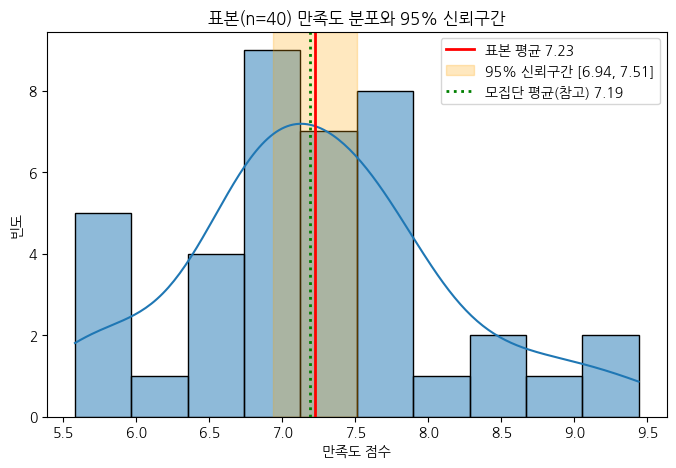

In [19]:
# [문제 5] Q3. 표본 데이터의 히스토그램을 그리고, 평균 및 신뢰구간을 함께 시각화해봅시다.
#  여기에 코드를 작성해주세요.
plt.figure(figsize=(8, 5))
sns.histplot(sample, bins=10, kde=True)

plt.axvline(sample_mean, color='red', linestyle='-', linewidth=2,
            label=f'표본 평균 {sample_mean:.2f}')
plt.axvspan(ci_lower, ci_upper, color='orange', alpha=0.25,
            label=f'95% 신뢰구간 [{ci_lower:.2f}, {ci_upper:.2f}]')
plt.axvline(population.mean(), color='green', linestyle=':', linewidth=2,
            label=f'모집단 평균(참고) {population.mean():.2f}')

plt.title("표본(n=40) 만족도 분포와 95% 신뢰구간")
plt.xlabel("만족도 점수")
plt.ylabel("빈도")
plt.legend()
plt.show()

In [20]:
# [문제 5] Q4. 신뢰구간의 결과에 따라 어떤 구체적인 마케팅 전략을 세울 수 있을까요?
# 여기에 의견을 작성해주세요.
print('''
[신뢰구간 결과]
- 표본 평균 7.23점, 95% 신뢰구간 [6.94, 7.51] (오차범위 약 ±0.29)
- 전체 고객의 평균 만족도는 약 6.9~7.5점 사이로 추정

[전략 1] 현재 수준을 구간으로 보고하고 기준선과 비교
- 점수 하나(7.23)가 아니라 "6.9~7.5점"으로 보고
- 가상의 목표가 7.5점이라면 구간 상한(7.51)이 겨우 걸치는 수준이라 "목표 달성"으로 단정하기 어려움
- 가상의 업계 평균이 7.0점이라면 구간(6.94~7.51)이 7.0을 포함하므로 "경쟁사보다 높다"고 말할 수 없음

[전략 2] 개선 캠페인의 효과를 구간 비교로 평가
- 캠페인 후 다시 조사해 신뢰구간을 계산하고, 이전 구간[6.94, 7.51]과 겹치지 않으면 의미 있는 변화로 판단
- 구간이 많이 겹치면 변화가 표본오차 때문일 수 있으므로 예산 확대를 서두르지 않음

[전략 3] 조사 설계 (정밀도 vs 비용)
- 현재 n=40의 오차범위는 ±0.29로 넓은 편
- 오차범위를 ±0.2로 줄이려면 표본이 약 80명 안팎으로 늘어야 함
- 중요한 의사결정(예산 배정 등)은 정밀한 조사를, 가벼운 모니터링은 작은 표본을 사용

[전략 4] 평균만 보지 않고 분포도 함께 관리
- 신뢰구간은 "평균"의 범위일 뿐 개별 고객 점수의 범위가 아님 (표본 점수는 약 5.6~9.4로 훨씬 넓게 분포)
- 평균이 괜찮아도 낮은 점수를 주는 고객층이 존재하므로, 낮은 점수 고객 대상 원인 파악과 이탈 방지 활동이 필요

[주의]
- "모평균이 이 구간에 있을 확률이 95%"가 아니라, "같은 방법으로 반복해서 구간을 만들면 약 95%가 모평균을 포함"한다는 뜻
''')


[신뢰구간 결과]
- 표본 평균 7.23점, 95% 신뢰구간 [6.94, 7.51] (오차범위 약 ±0.29)
- 전체 고객의 평균 만족도는 약 6.9~7.5점 사이로 추정

[전략 1] 현재 수준을 구간으로 보고하고 기준선과 비교
- 점수 하나(7.23)가 아니라 "6.9~7.5점"으로 보고
- 가상의 목표가 7.5점이라면 구간 상한(7.51)이 겨우 걸치는 수준이라 "목표 달성"으로 단정하기 어려움
- 가상의 업계 평균이 7.0점이라면 구간(6.94~7.51)이 7.0을 포함하므로 "경쟁사보다 높다"고 말할 수 없음

[전략 2] 개선 캠페인의 효과를 구간 비교로 평가
- 캠페인 후 다시 조사해 신뢰구간을 계산하고, 이전 구간[6.94, 7.51]과 겹치지 않으면 의미 있는 변화로 판단
- 구간이 많이 겹치면 변화가 표본오차 때문일 수 있으므로 예산 확대를 서두르지 않음

[전략 3] 조사 설계 (정밀도 vs 비용)
- 현재 n=40의 오차범위는 ±0.29로 넓은 편
- 오차범위를 ±0.2로 줄이려면 표본이 약 80명 안팎으로 늘어야 함
- 중요한 의사결정(예산 배정 등)은 정밀한 조사를, 가벼운 모니터링은 작은 표본을 사용

[전략 4] 평균만 보지 않고 분포도 함께 관리
- 신뢰구간은 "평균"의 범위일 뿐 개별 고객 점수의 범위가 아님 (표본 점수는 약 5.6~9.4로 훨씬 넓게 분포)
- 평균이 괜찮아도 낮은 점수를 주는 고객층이 존재하므로, 낮은 점수 고객 대상 원인 파악과 이탈 방지 활동이 필요

[주의]
- "모평균이 이 구간에 있을 확률이 95%"가 아니라, "같은 방법으로 반복해서 구간을 만들면 약 95%가 모평균을 포함"한다는 뜻



**🧠 데이터를 어떻게 읽을까요?**

- 신뢰구간은 몇 점에서 몇 점 사이인가요?

- 이 구간은 전체 모집단 평균을 포함하고 있나요?

- 이 결과를 바탕으로 고객 만족도가 충분히 높다고 말할 수 있을까요?

- 만약 신뢰구간이 너무 넓게 나왔다면, 그 이유는 무엇이고 어떻게 개선할 수 있을까요?

In [21]:
# [문제 5] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

print('''
1. 신뢰구간은 몇 점에서 몇 점 사이인가
- 95% 신뢰구간: [6.94, 7.51] (표본 평균 7.23 ± 오차범위 0.29)
- 표본 40명 기준, 전체 고객의 평균 만족도는 약 6.9점에서 7.5점 사이로 추정

2. 이 구간은 전체 모집단 평균을 포함하고 있는가
- 포함함: 모집단 평균 7.19가 구간 [6.94, 7.51] 안에 있음
- 단, 실제 조사에서는 모집단 평균을 알 수 없으므로 이런 확인은 학습용 시뮬레이션에서만 가능
- 95% 신뢰구간이 항상 모평균을 포함하는 것은 아님: 같은 방법으로 반복해서 구간을 만들면 약 95%가 포함하고 약 5%는 놓침

3. 이 결과를 바탕으로 고객 만족도가 충분히 높다고 말할 수 있는가
- "충분히 높다"는 기준점(예: 7점, 8점)이 있어야 판단 가능, 그 기준에 구간을 비교
- 기준이 7점(가상)이라면: 구간 하한 6.94가 7점보다 약간 낮아서 "7점 이상"이라고 단정하기 어려움
- 기준이 8점(가상)이라면: 구간 상한 7.51도 8점에 못 미쳐서 "높다"고 말하기 어려움
- 현재 결과로는 "10점 만점에 중상 수준(7점 안팎)"이라고 말하는 것이 안전
- 평균만 보고 판단하지 않고, 개별 점수 분포(표본 점수 약 5.6~9.4)도 함께 봐야 함

4. 신뢰구간이 너무 넓게 나왔다면 그 이유와 개선 방법
- 이유 1: 표본 크기가 작음 (표준오차 = s/√n, n이 작을수록 SE가 커짐)
- 이유 2: 데이터가 많이 흩어져 있음 (표본 표준편차 s가 큼)
- 이유 3: 신뢰수준이 높음 (99%는 95%보다 임계값이 커서 구간이 넓어짐)
- 개선 1: 표본 크기 늘리기 → 현재 n=40의 오차범위 ±0.29를 ±0.2로 줄이려면 약 80명 안팎, 표본을 4배(n=160)로 늘리면 오차범위는 절반 수준(약 ±0.14)
- 개선 2: 신뢰수준을 낮추기 (예: 99% → 95%), 단 확신이 줄어드는 trade-off가 있음
- 개선 3: 데이터의 흩어짐 줄이기 (설문 문항을 명확하게 하거나, 고객군을 나누어 조사하는 층화추출 등)
''')

# 근거 수치
print(f"표본 평균: {sample_mean:.3f} / 95% 신뢰구간: [{ci_lower:.3f}, {ci_upper:.3f}] / 오차범위: ±{margin:.3f}")
print(f"모집단 평균 {population.mean():.3f} 포함 여부: {ci_lower <= population.mean() <= ci_upper}")
print(f"표본 점수 범위: {sample.min():.2f} ~ {sample.max():.2f}")


1. 신뢰구간은 몇 점에서 몇 점 사이인가
- 95% 신뢰구간: [6.94, 7.51] (표본 평균 7.23 ± 오차범위 0.29)
- 표본 40명 기준, 전체 고객의 평균 만족도는 약 6.9점에서 7.5점 사이로 추정

2. 이 구간은 전체 모집단 평균을 포함하고 있는가
- 포함함: 모집단 평균 7.19가 구간 [6.94, 7.51] 안에 있음
- 단, 실제 조사에서는 모집단 평균을 알 수 없으므로 이런 확인은 학습용 시뮬레이션에서만 가능
- 95% 신뢰구간이 항상 모평균을 포함하는 것은 아님: 같은 방법으로 반복해서 구간을 만들면 약 95%가 포함하고 약 5%는 놓침

3. 이 결과를 바탕으로 고객 만족도가 충분히 높다고 말할 수 있는가
- "충분히 높다"는 기준점(예: 7점, 8점)이 있어야 판단 가능, 그 기준에 구간을 비교
- 기준이 7점(가상)이라면: 구간 하한 6.94가 7점보다 약간 낮아서 "7점 이상"이라고 단정하기 어려움
- 기준이 8점(가상)이라면: 구간 상한 7.51도 8점에 못 미쳐서 "높다"고 말하기 어려움
- 현재 결과로는 "10점 만점에 중상 수준(7점 안팎)"이라고 말하는 것이 안전
- 평균만 보고 판단하지 않고, 개별 점수 분포(표본 점수 약 5.6~9.4)도 함께 봐야 함

4. 신뢰구간이 너무 넓게 나왔다면 그 이유와 개선 방법
- 이유 1: 표본 크기가 작음 (표준오차 = s/√n, n이 작을수록 SE가 커짐)
- 이유 2: 데이터가 많이 흩어져 있음 (표본 표준편차 s가 큼)
- 이유 3: 신뢰수준이 높음 (99%는 95%보다 임계값이 커서 구간이 넓어짐)
- 개선 1: 표본 크기 늘리기 → 현재 n=40의 오차범위 ±0.29를 ±0.2로 줄이려면 약 80명 안팎, 표본을 4배(n=160)로 늘리면 오차범위는 절반 수준(약 ±0.14)
- 개선 2: 신뢰수준을 낮추기 (예: 99% → 95%), 단 확신이 줄어드는 trade-off가 있음
- 개선 3: 데이터의 흩어짐 줄이기 (설문 문항을 명확하게 하거나, 고객군을 나